# EDA, чекпойнт 2. Деформации поверхности по InSAR

Трек DL. Проект — мониторинг инфраструктуры по спутниковым данным, пилотный регион Норильск.

## 0. Постановка

В проекте четыре задачи. Первые две решаются по радарным данным, вторые две — по оптике.

| № | Задача | Данные | Что ищем |
|---|---|---|---|
| 1 | Деформации дамб хвостохранилищ и бортов карьеров | InSAR (Sentinel-1) | медленное смещение, мм в месяц |
| 2 | Просадки мерзлоты под трубами, резервуарами, опорами | InSAR (Sentinel-1) | сезонные колебания и тренд |
| 3 | Деревья в охранной зоне ЛЭП | оптика (Sentinel-2) | высота деревьев рядом с проводами |
| 4 | Пожарный риск леса у ЛЭП | оптика + погода | вероятность возгорания |

Размеченных данных по нашим объектам (Норильск, хвостохранилища, мерзлота) в открытом доступе нет. Поэтому для первого EDA мы взяли самый близкий открытый датасет с реальными интерферограммами Sentinel-1 и ручной разметкой:

**Global Co-seismic InSAR Dataset for Deep Learning** (Liu Xu, 2025, Zenodo, doi 10.5281/zenodo.15382562, CC-BY 4.0). Это патчи 224×224, нарезанные из 353 интерферограмм по 62 землетрясениям 2015–2024 годов. Два класса: `deformation` (есть след землетрясения) и `noise` (деформации нет), по 14 000 патчей.

Коротко про сами данные. Радар измеряет фазу отражённого сигнала. Если взять два снимка одного места в разное время и вычесть фазы, получится интерферограмма — по ней видно, насколько сдвинулась поверхность. Фаза циклическая (от −π до π), поэтому смещение выглядит как цветные полосы: одна полоса у Sentinel-1 соответствует примерно 2.8 см. Мешают атмосфера (даёт ложные полосы) и декорреляция — на воде, в лесу и на снегу фаза превращается в шум.

Сначала мы думали, что в датасете есть маски деформаций и можно ставить задачу сегментации. Оказалось, что это не так:

1. масок нет, есть только метка класса для всего патча, то есть задача классификация;
2. авторы уже применили аугментации (повороты, отражения, масштаб) и сохранили результат, поэтому в данных много копий одних и тех же участков;
3. информации о том, из какого землетрясения взят патч, нет, так что разбить выборку по событиям нельзя;
4. в каждом файле один канал uint8 — это фаза, пересчитанная из (−π, π] в 0–255. Ноль при этом ещё и означает «нет данных».

Дальше всё это проверяем.


In [2]:
import os, time, warnings, zipfile
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageFilter
warnings.filterwarnings('ignore')

# архив v2 с Zenodo и папка, куда он распаковывается (внутри будут deformation/ и noise/)
ROOT = Path(r'C:\Users\madiv\Documents\Claude\Projects\sattelited')
ZIP_PATH = ROOT / 'Coseismic InSAR Image Patches (224 pixels × 224 pixels).zip'
DATA_DIR = ROOT / 'data'

if len(list(DATA_DIR.glob('*/*.tif'))) < 28000:        # данных нет или распакованы не полностью
    with zipfile.ZipFile(ZIP_PATH) as z:
        for f in z.infolist():
            p = DATA_DIR / f.filename
            if f.is_dir() or (p.exists() and p.stat().st_size == f.file_size):
                continue
            z.extract(f, DATA_DIR)
assert (DATA_DIR/'deformation').exists() and (DATA_DIR/'noise').exists()

CACHE = Path('./cache'); CACHE.mkdir(exist_ok=True)   # сюда сохраняем долгие расчёты
SEED = 42; rng = np.random.default_rng(SEED)
K = 2*np.pi/256                                        # перевод 0..255 -> радианы

def wdiff(ph, axis):
    # разность соседних пикселей с учётом цикличности фазы
    return np.angle(np.exp(1j*np.diff(ph, axis=axis)))


## 1. Что лежит в датасете

In [3]:
rows = []
for cls in ['deformation', 'noise']:
    for f in sorted((DATA_DIR/cls).glob('*.tif'), key=lambda p: int(p.stem) if p.stem.isdigit() else p.stem):
        rows.append({'cls': cls, 'path': str(f), 'id': f.stem, 'bytes': f.stat().st_size})
inv = pd.DataFrame(rows)
inv['label'] = (inv.cls == 'deformation').astype(int)
print(inv.groupby('cls').agg(n=('path', 'size'), MB=('bytes', lambda s: s.sum()/1e6)).round(1))


                 n     MB
cls                      
deformation  14000  704.5
noise        14000  705.1


In [4]:
# Проходим по всем файлам один раз: считаем признаки и сохраняем уменьшенную копию 56x56.
# Это занимает около 10 минут, поэтому результат кладём в кеш.
def img_features(a):
    h, w = a.shape
    ph = a.astype(np.float32)*K
    dx, dy = wdiff(ph, 1), wdiff(ph, 0)
    gm = np.hypot(dx[:-1, :], dy[:, :-1])                     # градиент фазы, рад/пиксель
    z = np.exp(1j*ph)
    coh = np.abs(z[:h//7*7, :w//7*7].reshape(h//7, 7, w//7, 7).mean(axis=(1, 3)))  # гладкость в окнах 7x7
    return dict(h=h, w=w, mean=float(a.mean()), std=float(a.std()),
                zero_frac=float((a == 0).mean()),             # доля пикселей без данных
                jump_frac=float(((np.abs(dx) > np.pi/2).mean() + (np.abs(dy) > np.pi/2).mean())/2),
                grad_mean=float(gm.mean()), grad_p90=float(np.percentile(gm, 90)),
                coh_mean=float(coh.mean()), coh_low_frac=float((coh < 0.3).mean()),
                R=float(np.abs(z.mean())),                    # насколько фаза патча сосредоточена около одного значения
                n_unique=int(len(np.unique(a))))

feat_path = CACHE/'features.npz'
if feat_path.exists():
    z = np.load(feat_path, allow_pickle=True)
    F = pd.DataFrame(z['F'].item()); thumbs = z['thumbs']; hist = z['hist']
else:
    feats = []; thumbs = np.zeros((len(inv), 56, 56), np.uint8); hist = np.zeros((len(inv), 256), np.int32)
    for i, p in enumerate(inv.path):
        im = Image.open(p); a = np.array(im)
        d = img_features(a); d['mode'] = im.mode; feats.append(d)
        hist[i] = np.bincount(a.ravel(), minlength=256)
        thumbs[i] = np.array(im.resize((56, 56), Image.BILINEAR))
    F = pd.DataFrame(feats)
    np.savez_compressed(feat_path, F=F.to_dict('list'), thumbs=thumbs, hist=hist)
df = pd.concat([inv, F], axis=1)
print('Режим изображений:', df['mode'].value_counts().to_dict())
print('Размеры патчей:'); print(df.groupby(['cls', 'h', 'w']).size())


Режим изображений: {'L': 28000}
Размеры патчей:
cls          h    w  
deformation  224  224    13984
             256  256       16
noise        224  224    14000
dtype: int64


Все патчи одноканальные, uint8, без координат и без канала когерентности. 16 патчей имеют размер 256×256 вместо 224×224, причём все они в классе `deformation`. Перед обучением их надо обрезать или выкинуть.

Жаль, что нет когерентности: обычно именно по ней понимают, можно ли доверять пикселю. Для Норильска её придётся считать самим.

## 2. Примеры патчей

deformation


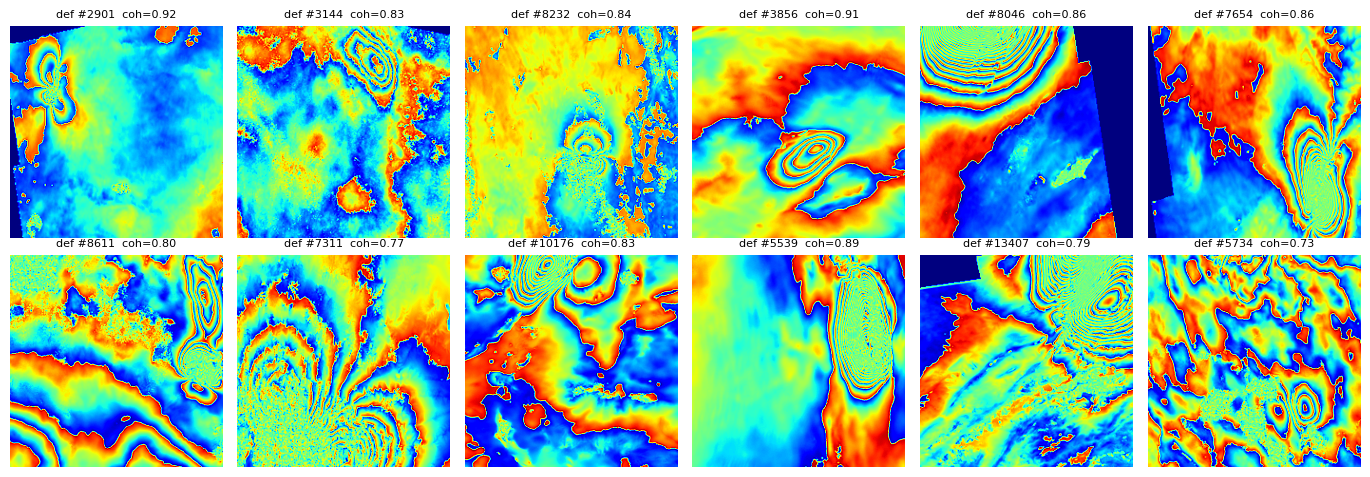

noise


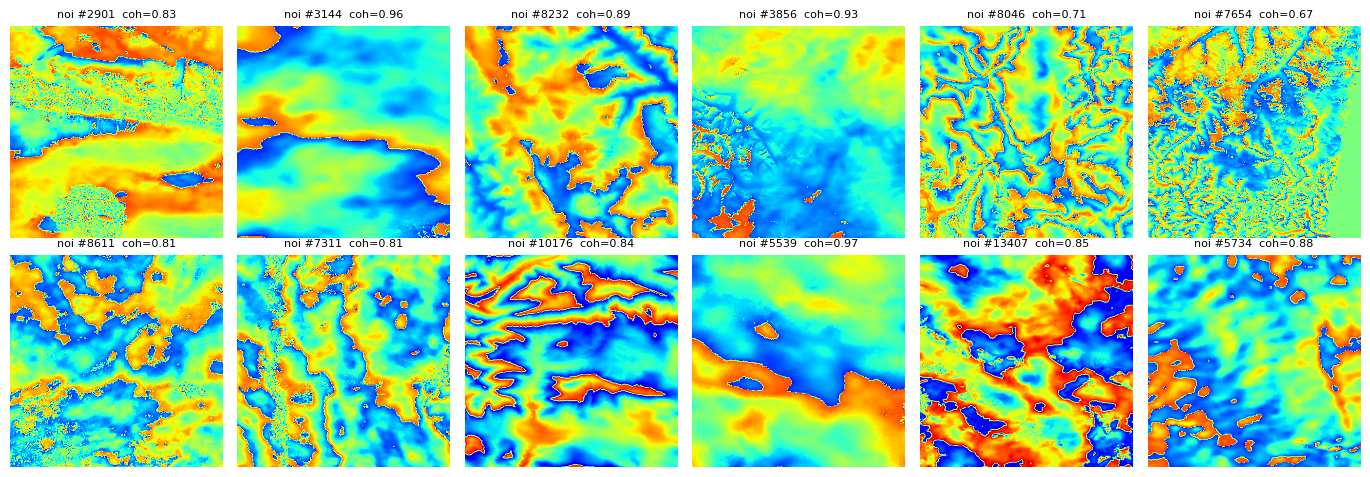

In [5]:
def show_grid(paths, titles, ncol=6):
    nrow = int(np.ceil(len(paths)/ncol))
    fig, ax = plt.subplots(nrow, ncol, figsize=(2.3*ncol, 2.4*nrow))
    for a in np.atleast_1d(ax).ravel(): a.axis('off')
    for a, p, t in zip(np.atleast_1d(ax).ravel(), paths, titles):
        a.imshow(np.array(Image.open(p)), cmap='jet', vmin=0, vmax=255); a.set_title(t, fontsize=8)
    plt.tight_layout(); plt.show()

for cls in ['deformation', 'noise']:
    sub = df[df.cls == cls].sample(12, random_state=SEED)
    print(cls)
    show_grid(sub.path, [f'{cls[:3]} #{i}  coh={c:.2f}' for i, c in zip(sub.id, sub.coh_mean)])


Рисуем в палитре jet, как принято для интерферограмм: один проход по радуге эт одна полоса. В `deformation` видны характерные кольца и лепестки от землетрясений. В `noise` в основном плавные пятна от атмосферы и зернистые участки, где сигнал потерян. На глаз классы различаются, но не всегда: атмосфера тоже может давать полосы.

## 3. Особенности данных

### 3.1 Значения пикселей

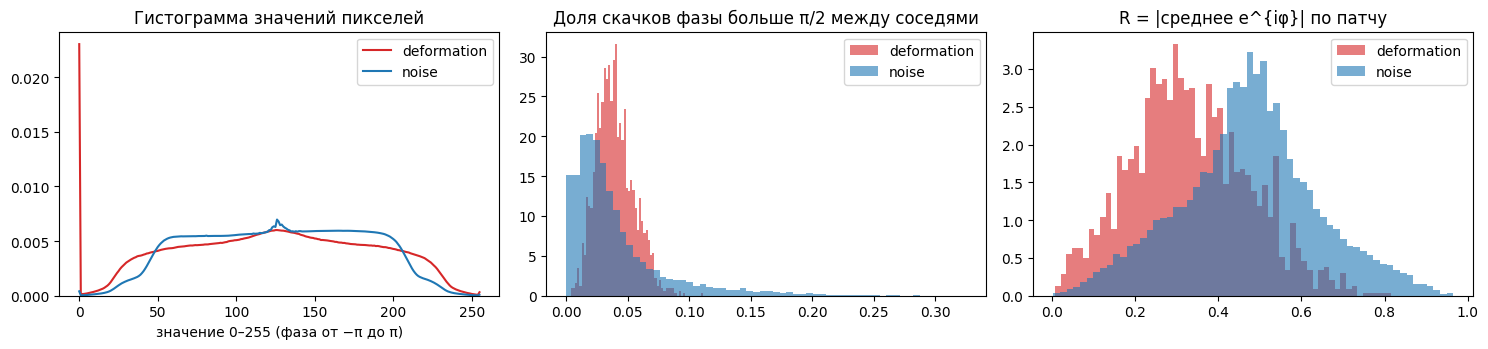

                mean     std  grad_mean  coh_mean      R  zero_frac
cls                                                                
deformation  124.323  57.336      0.449     0.842  0.331      0.023
noise        128.005  48.095      0.365     0.876  0.473      0.000


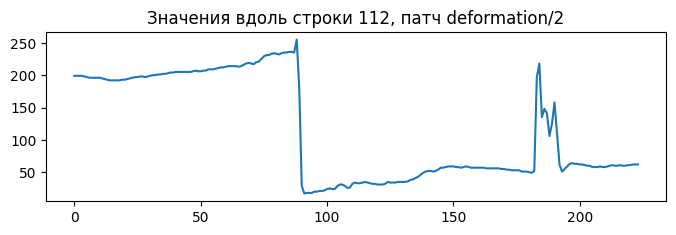

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for cls, c in [('deformation', 'C3'), ('noise', 'C0')]:
    m = (df.cls == cls).values
    hh = hist[m].sum(0)
    ax[0].plot(hh/hh.sum(), color=c, label=cls)
    ax[1].hist(df.jump_frac[m], bins=60, alpha=.6, color=c, label=cls, density=True)
    ax[2].hist(df.R[m], bins=60, alpha=.6, color=c, label=cls, density=True)
ax[0].set_title('Гистограмма значений пикселей'); ax[0].set_xlabel('значение 0–255 (фаза от −π до π)'); ax[0].set_ylim(0, None)
ax[1].set_title('Доля скачков фазы больше π/2 между соседями')
ax[2].set_title('R = |среднее e^{iφ}| по патчу')
for a in ax: a.legend()
plt.tight_layout(); plt.show()
print(df.groupby('cls')[['mean', 'std', 'grad_mean', 'coh_mean', 'R', 'zero_frac']].mean().round(3))

# профиль вдоль строки одного патча: видно, что фаза "заворачивается"
a = np.array(Image.open(df.path[1]))
plt.figure(figsize=(8, 2.2)); plt.plot(a[112]); plt.title('Значения вдоль строки 112, патч deformation/' + df.id[1]); plt.show()


Гистограмма с центром около 128 (это нулевая фаза) и отдельным пиком в нуле. Пик в нуле это пиксели без данных, а не фаза.

На профиле видно, что значение растет до 255 и потом резко падает почти до 0 (или наоборот). Это не резкая граница на картинке, а просто переход через край цикла: 255 и 0 соседние значения фазы. Отсюда три вывода:

- средняя яркость патча ничего не говорит о классе (124 и 128), с такими данными нельзя работать как с обычной серой картинкой;
- менять яркость и контраст нельзя, пушто это ломает фазу (подробнее в разделе 5);
- на вход модели лучше подавать не число 0–255, а пару cos φ и sin φ, тогда разрыва между 255 и 0 нет. Пиксели без данных нужно отмечать отдельно.

Классы различаются не значениями, а рисунком. У `deformation` фаза из-за полос разбросана по всему кругу (R около 0.3), у `noise` она ближе к одному значению (R около 0.5). Градиент фазы у `deformation` в среднем тоже больше.

### 3.2 Баланс классов

cls
deformation    14000
noise          14000
Name: count, dtype: int64


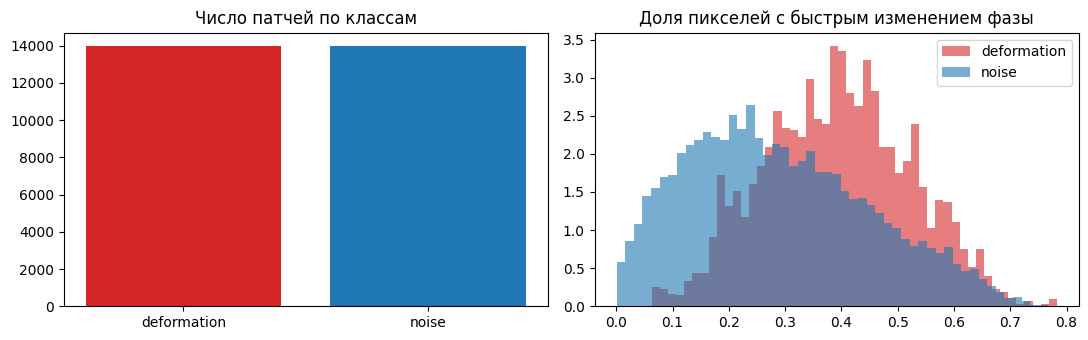

               count   mean    std    min    25%    50%    75%    max
cls                                                                  
deformation  14000.0  0.393  0.129  0.063  0.298  0.394  0.484  0.783
noise        14000.0  0.288  0.161  0.001  0.161  0.269  0.400  0.766


In [7]:
cnt = df.cls.value_counts()
print(cnt)

# Масок нет, поэтому долю "пикселей с сигналом" оцениваем грубо:
# считаем пиксели, где фаза меняется быстро (градиент > 0.5 рад/пиксель на копии 56x56)
def fringe_frac(t, thr=0.5):
    ph = t.astype(np.float32)*K
    dx, dy = wdiff(ph, 1), wdiff(ph, 0)
    return float((np.hypot(dx[:-1], dy[:, :-1]) > thr).mean())
df['fringe_frac'] = [fringe_frac(t) for t in thumbs]

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].bar(cnt.index, cnt.values, color=['C3', 'C0']); ax[0].set_title('Число патчей по классам')
for cls, c in [('deformation', 'C3'), ('noise', 'C0')]:
    ax[1].hist(df.fringe_frac[df.cls == cls], bins=50, alpha=.6, color=c, label=cls, density=True)
ax[1].set_title('Доля пикселей с быстрым изменением фазы'); ax[1].legend()
plt.tight_layout(); plt.show()
print(df.groupby('cls').fringe_frac.describe().round(3))


По патчам классы сбалансированы ровно 50 на 50. Но это сделано искусственно. В реальном мониторинге участков с деформацией очень мало, доли процента площади. Поэтому accuracy на таком датасете мало что значит для нашей задачи, и в будущем мы будем смотреть на PR-AUC и на полноту при фиксированном уровне ложных срабатываний.

По пикселям точный баланс посчитать нельзя, потому что масок нет. Наша грубая оценка показывает, что участки с быстрой сменой фазы занимают в `deformation` в среднем 39% патча, а в `noise` 29%. быстрые изменения фазы бывают и без деформации (атмосфера, шум). То есть по одному этому признаку классы не разделить, а для сегментации нужна настоящая разметка по пикселям.

### 3.3 Качество данных и выбросы

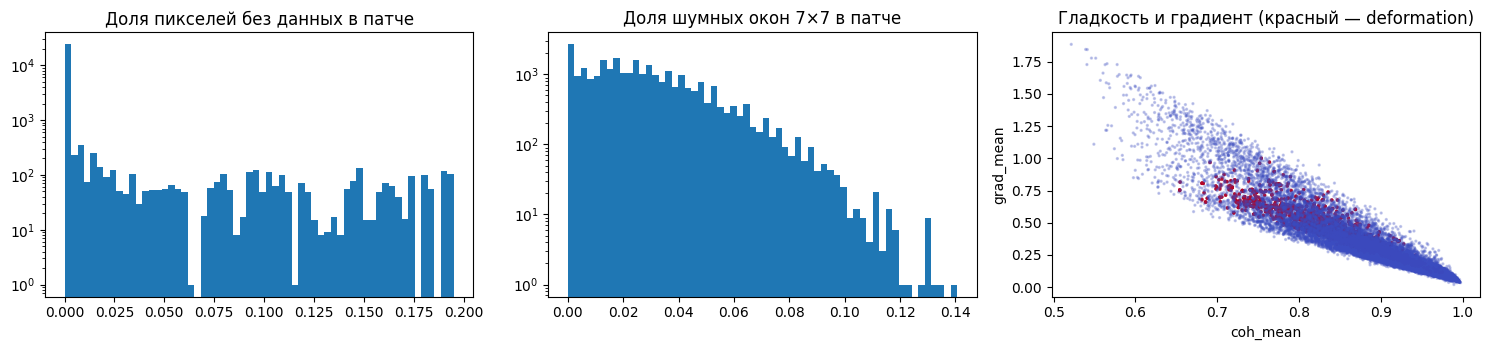

cls                        deformation  noise
без данных > 10% пикселей         1520      9
шумных окон > 50%                    0      0
почти константа (std < 5)            0      0
размер не 224×224                   16      0


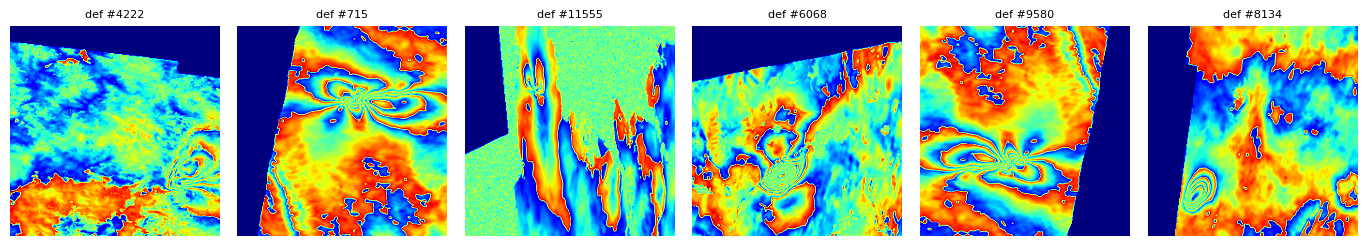

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
ax[0].hist(df.zero_frac, bins=60, log=True); ax[0].set_title('Доля пикселей без данных в патче')
ax[1].hist(df.coh_low_frac, bins=60, log=True); ax[1].set_title('Доля шумных окон 7×7 в патче')
ax[2].scatter(df.coh_mean, df.grad_mean, s=2, alpha=.25, c=df.label, cmap='coolwarm')
ax[2].set_xlabel('coh_mean'); ax[2].set_ylabel('grad_mean'); ax[2].set_title('Гладкость и градиент (красный — deformation)')
plt.tight_layout(); plt.show()

bad = {'без данных > 10% пикселей': df.zero_frac > 0.10,
       'шумных окон > 50%': df.coh_low_frac > 0.50,
       'почти константа (std < 5)': df['std'] < 5,
       'размер не 224×224': (df.h != 224) | (df.w != 224)}
print(pd.DataFrame({k: v.groupby(df.cls).sum() for k, v in bad.items()}).T)

sub = df[bad['без данных > 10% пикселей']].sample(6, random_state=SEED)
show_grid(sub.path, [f'{c[:3]} #{i}' for i, c in zip(sub.id, sub.cls)])


Полностью испорченных патчей (пустых или целиком шумных) мы не нашли. Но есть проблема другого рода.

У части патчей есть темно-синие углы или полосы — это край снимка, где данных нет (значение 0). Таких патчей с долей пустых пикселей больше 10% в классе `deformation` 1520, а в `noise` всего 9. Патчи нестандартного размера тоже все в `deformation`. Видимо, классы готовили по-разному. Это опасно: модель может выучить правило есть темный угол, значит, мол, деформация и вообще не смотреть на полосы. При обучении такие области надо маскировать.

Зернистые участки (декорреляция) встречаются в обоих классах, но занимают небольшую часть патча. Для Норильска это будет главной проблемой, потому что там большую часть года лежит снег. Поэтому в своих данных мы обязательно сохраним канал когерентности и будем брать в основном летние пары снимков.

### 3.4 Дубликаты

В readme написано, что патчи уже аугментированы поворотами и отражениями. Проверим, сколько в данных таких копий. Для каждого патча считаем хеш, который не меняется при поворотах на 90° и отражениях (всего 8 вариантов). Патчи с одинаковым хешем дополнительно сравниваем попиксельно.

Патчей: 28000  уникальных: 16446
Размер группы -> сколько таких групп:
n
1     13928
2        36
3        66
4      1544
6         5
7        89
8       654
11        2
12       64
15       16
16       37
23        1
24        4
Name: count, dtype: int64
Групп с разными метками внутри: 0
Доля патчей, у которых есть копия: 0.503


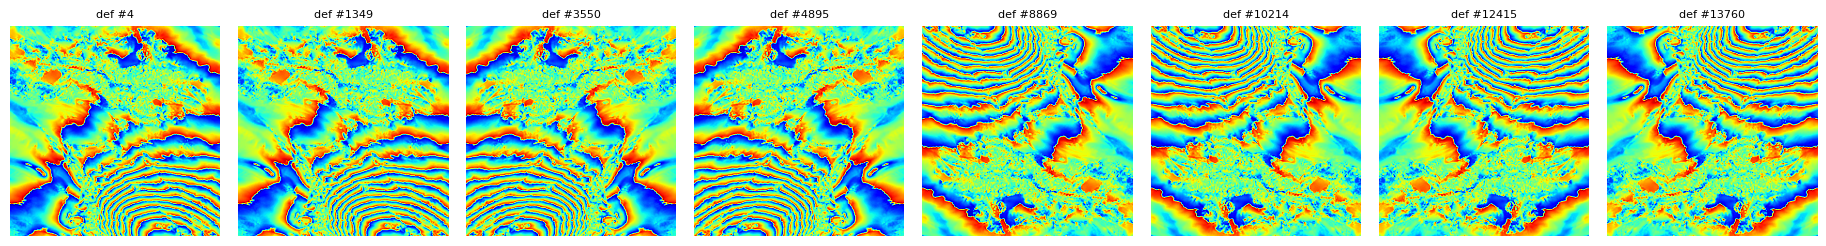

In [9]:
def variants(t):                       # 4 поворота и их отражения
    for k in range(4):
        r = np.rot90(t, k); yield r; yield r[:, ::-1]

def canon_hash(t56):
    t16 = np.array(Image.fromarray(t56).resize((16, 16), Image.BILINEAR))
    return min(np.packbits(wdiff(v.astype(np.float32)*K, 1) > 0).tobytes() for v in variants(t16))

def phase_dist(t1, t2):                # средняя разность фаз, минимум по 8 вариантам
    p1 = t1.astype(np.float32)*K
    return min(float(np.abs(np.angle(np.exp(1j*(p1 - v.astype(np.float32)*K)))).mean()) for v in variants(t2))

grp_path = CACHE/'groups.npz'
if grp_path.exists():
    group = np.load(grp_path)['group']
else:
    cand = pd.factorize([canon_hash(t) for t in thumbs])[0]
    group = np.arange(len(df)); dists = []
    for cid in np.unique(cand):
        members = np.flatnonzero(cand == cid)
        reps = [members[0]]
        for m in members[1:]:
            for r in reps:
                dd = phase_dist(thumbs[m], thumbs[r]); dists.append(dd)
                if dd < 0.35: group[m] = group[r]; break     # считаем копией
            else:
                reps.append(m)
    np.savez(grp_path, group=group, dists=np.array(dists))
df['group'] = pd.factorize(group)[0]

g = df.groupby('group').agg(n=('id', 'size'), n_cls=('cls', 'nunique'))
print('Патчей:', len(df), ' уникальных:', len(g))
print('Размер группы -> сколько таких групп:'); print(g.n.value_counts().sort_index())
print('Групп с разными метками внутри:', int((g.n_cls > 1).sum()))
print('Доля патчей, у которых есть копия:', round((df.groupby('group').id.transform('size') > 1).mean(), 3))

sub = df[df.group == g[g.n == 8].index[0]]
show_grid(sub.path, [f'{c[:3]} #{i}' for i, c in zip(sub.id, sub.cls)], ncol=8)


Из 28 000 патчей уникальных только 16 446. У половины патчей есть хотя бы одна копия, которая отличается только поворотом или отражением. Чаще всего встречаются группы по 4 патча (четыре поворота) и по 8 (все повороты и отражения). Это совпадает с тем, что написано в readme. Копии с масштабом и сдвигом наш хеш не находит, так что на самом деле повторов ещё больше. Метки внутри групп всегда совпадают.

Из-за этого нельзя делить выборку на train и test случайно: копия тестового патча попадёт в обучение, и качество получится завышенным. Правильнее всего было бы делить по землетрясениям, но этой информации в датасете нет. Поэтому мы делим по найденным группам копий: вся группа целиком идёт либо в train, либо в test.

Для своих данных по Норильску сразу решаем: выборку делим по объектам и по времени, а аугментации применяем только во время обучения и не сохраняем в датасет.

## 4. Бейзлайн

Нейросеть на этом этапе не обучаем, берём две простые модели из sklearn: логистическую регрессию и градиентный бустинг (HistGradientBoosting). Признаки эт уменьшенный до 28×28 патч в виде cos φ и sin φ (1568 чисел) плюс 8 признаков, посчитанных выше. Сравниваем два способа разбиения: случайный и по группам копий. В тест идёт 25%.

In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score, average_precision_score,
                             confusion_matrix, RocCurveDisplay, PrecisionRecallDisplay)

t28 = np.stack([np.array(Image.fromarray(t).resize((28, 28), Image.BILINEAR)) for t in thumbs]).astype(np.float32)*K
hand = ['jump_frac', 'grad_mean', 'grad_p90', 'coh_mean', 'coh_low_frac', 'R', 'zero_frac', 'fringe_frac']
X = np.concatenate([np.cos(t28).reshape(len(df), -1), np.sin(t28).reshape(len(df), -1),
                    df[hand].values.astype(np.float32)], 1)
y = df.label.values; groups = df.group.values
idx = np.arange(len(df))

def split(kind):
    if kind == 'random':
        return train_test_split(idx, test_size=0.25, random_state=SEED, stratify=y)
    return next(GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=SEED).split(idx, y, groups))

def make_model(name):
    if name == 'LogReg':
        return make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=2000))
    return HistGradientBoostingClassifier(max_iter=300, learning_rate=0.08, random_state=SEED)

pred_path = CACHE/'baseline_preds.npz'
if pred_path.exists():
    preds = np.load(pred_path, allow_pickle=True)['preds'].item()
    R = pd.read_csv(CACHE/'baseline_results.csv')
else:
    results = []; preds = {}
    for kind in ['random', 'group']:
        tr, te = split(kind)
        for name in ['LogReg', 'HGB']:
            t0 = time.time()
            p = make_model(name).fit(X[tr], y[tr]).predict_proba(X[te])[:, 1]
            preds[(kind, name)] = (te, p)
            results.append(dict(split=kind, model=name, test_n=len(te),
                                test_groups_seen_in_train=round(np.isin(groups[te], groups[tr]).mean(), 3),
                                acc=accuracy_score(y[te], p > 0.5), f1=f1_score(y[te], p > 0.5),
                                roc_auc=roc_auc_score(y[te], p), pr_auc=average_precision_score(y[te], p),
                                fit_s=round(time.time()-t0)))
    R = pd.DataFrame(results).round(3)
    R.to_csv(CACHE/'baseline_results.csv', index=False)
    np.savez(pred_path, preds=np.array(preds, dtype=object))
print(R.to_string(index=False))


  File "c:\Users\madiv\AppData\Local\Programs\Python\Python312\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\madiv\AppData\Local\Programs\Python\Python312\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\madiv\AppData\Local\Programs\Python\Python312\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Users\madiv\AppData\Local\Programs\Python\Python312\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^


 split  model  test_n  test_groups_seen_in_train   acc    f1  roc_auc  pr_auc  fit_s
random LogReg    7000                        0.5 0.832 0.831    0.904   0.901      8
random    HGB    7000                        0.5 0.948 0.949    0.991   0.989     88
 group LogReg    7041                        0.0 0.816 0.810    0.896   0.896      8
 group    HGB    7041                        0.0 0.936 0.937    0.986   0.985     62


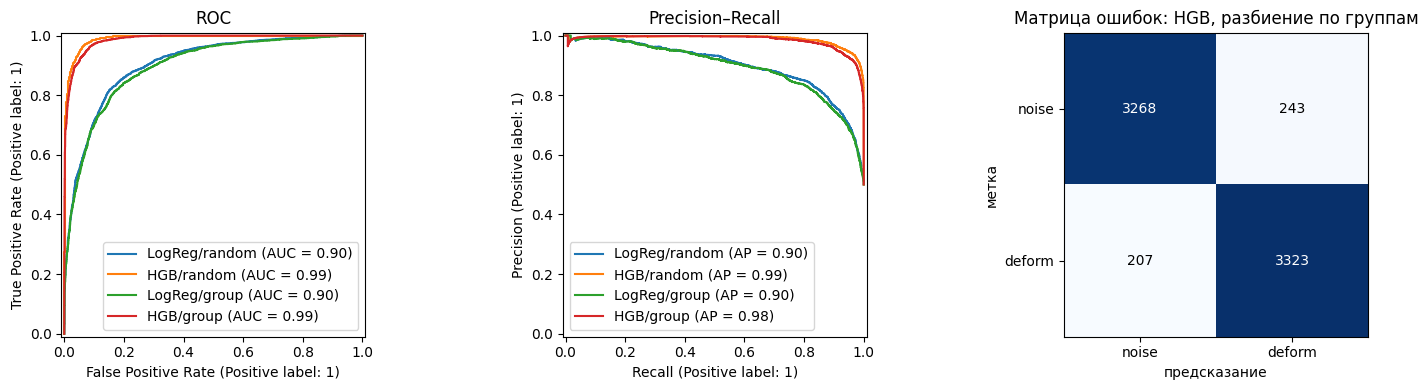

ROC-AUC только на 8 признаках: 0.986


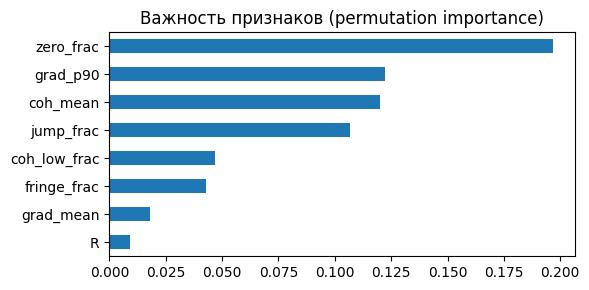

noise, но модель говорит deformation:


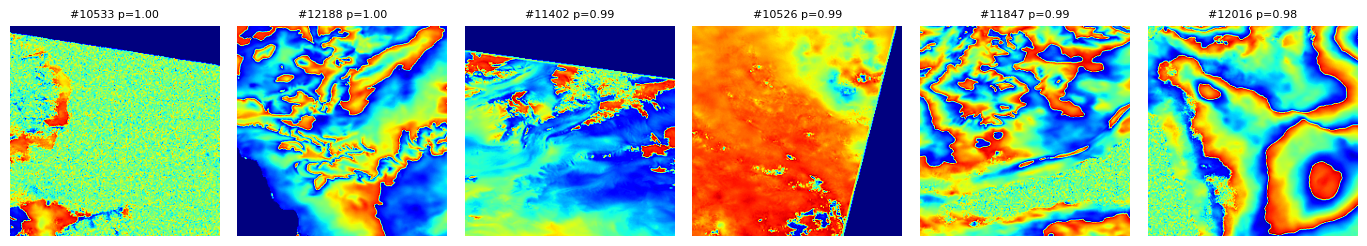

deformation, но модель говорит noise:


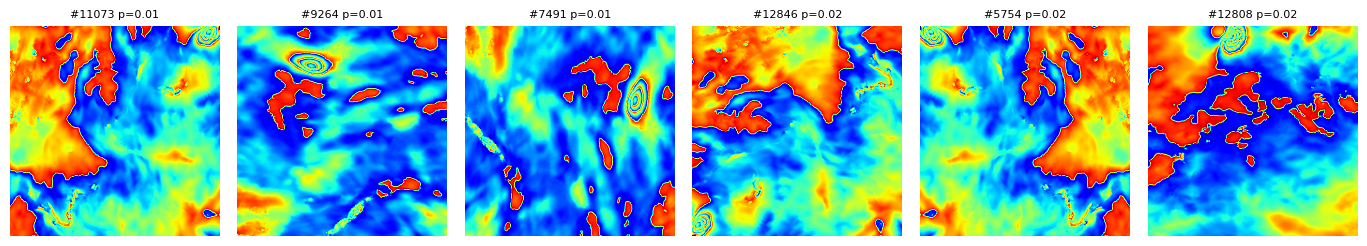

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for (kind, name), (te, p) in preds.items():
    RocCurveDisplay.from_predictions(y[te], p, name=f'{name}/{kind}', ax=ax[0])
    PrecisionRecallDisplay.from_predictions(y[te], p, name=f'{name}/{kind}', ax=ax[1])
ax[0].set_title('ROC'); ax[1].set_title('Precision–Recall')
te, p = preds[('group', 'HGB')]
cm = confusion_matrix(y[te], p > 0.5)
ax[2].imshow(cm, cmap='Blues'); ax[2].set_xticks([0, 1], ['noise', 'deform']); ax[2].set_yticks([0, 1], ['noise', 'deform'])
for i in range(2):
    for j in range(2): ax[2].text(j, i, cm[i, j], ha='center', va='center', color='w' if cm[i, j] > cm.max()/2 else 'k')
ax[2].set_title('Матрица ошибок: HGB, разбиение по группам'); ax[2].set_xlabel('предсказание'); ax[2].set_ylabel('метка')
plt.tight_layout(); plt.show()

# тот же бустинг только на 8 посчитанных признаках, без картинки
tr, te = split('group')
hgb = make_model('HGB').fit(X[tr][:, -8:], y[tr])
print('ROC-AUC только на 8 признаках:', round(roc_auc_score(y[te], hgb.predict_proba(X[te][:, -8:])[:, 1]), 3))
pi = permutation_importance(hgb, X[te][:, -8:], y[te], n_repeats=5, random_state=SEED, scoring='roc_auc')
pd.Series(pi.importances_mean, index=hand).sort_values().plot.barh(figsize=(6, 3), title='Важность признаков (permutation importance)')
plt.tight_layout(); plt.show()

# самые уверенные ошибки
te, p = preds[('group', 'HGB')]
sub = df.iloc[te].assign(p=p)
fp = sub[sub.label == 0].nlargest(6, 'p'); fn = sub[sub.label == 1].nsmallest(6, 'p')
print('noise, но модель говорит deformation:'); show_grid(fp.path, [f'#{i} p={v:.2f}' for i, v in zip(fp.id, fp.p)])
print('deformation, но модель говорит noise:'); show_grid(fn.path, [f'#{i} p={v:.2f}' for i, v in zip(fn.id, fn.p)])


Результаты на разбиении по группам (в тесте 7041 патч, пересечений с train по группам нет):

| Модель | accuracy | F1 | ROC-AUC | PR-AUC |
|---|---|---|---|---|
| Логистическая регрессия | 0.816 | 0.810 | 0.896 | 0.896 |
| HistGradientBoosting | 0.938 | 0.938 | 0.987 | 0.985 |

Это качество фиксируем как бейзлайн. 

Что мы здесь увидели???

При случайном разбиении у половины тестовых патчей есть копия в train, и метрики получаются выше: accuracy 0.949 против 0.938 у бустинга. Разница есть, но небольшая. Мы ожидали, что она будет больше.

Объяснение, скорее всего, в том, что задача сама по себе простая. Бустинг только на 8 признаках, без самой картинки, даёт ROC-AUC 0.986, тО есть почти столько же, сколько с картинкой. Следы землетрясений крупные и контрастные, их легко отличить по общей статистике патча. Для дамб и мерзлоты, где смещения — миллиметры, так легко не будет.

Ошибок обоих типов примерно поровну (230 и 207). Если посмотреть на примеры, видно следующее. Ложные срабатывания это патчи `noise` с тёмным углом без данных или с плотными полосами от атмосферы. Первое подтверждает опасение из раздела 3.3: модель частично ориентируется на пустые углы. Пропуски патчи, где след деформации маленький и занимает уголок, а остальное атмосфера. Наши признаки считаются по всему патчу и такой маленький сигнал не видят. Здесь должна помочь свёрточная сеть.

## 5. 

Посмотрим на одном патче, что разные преобразования делают с фазой.

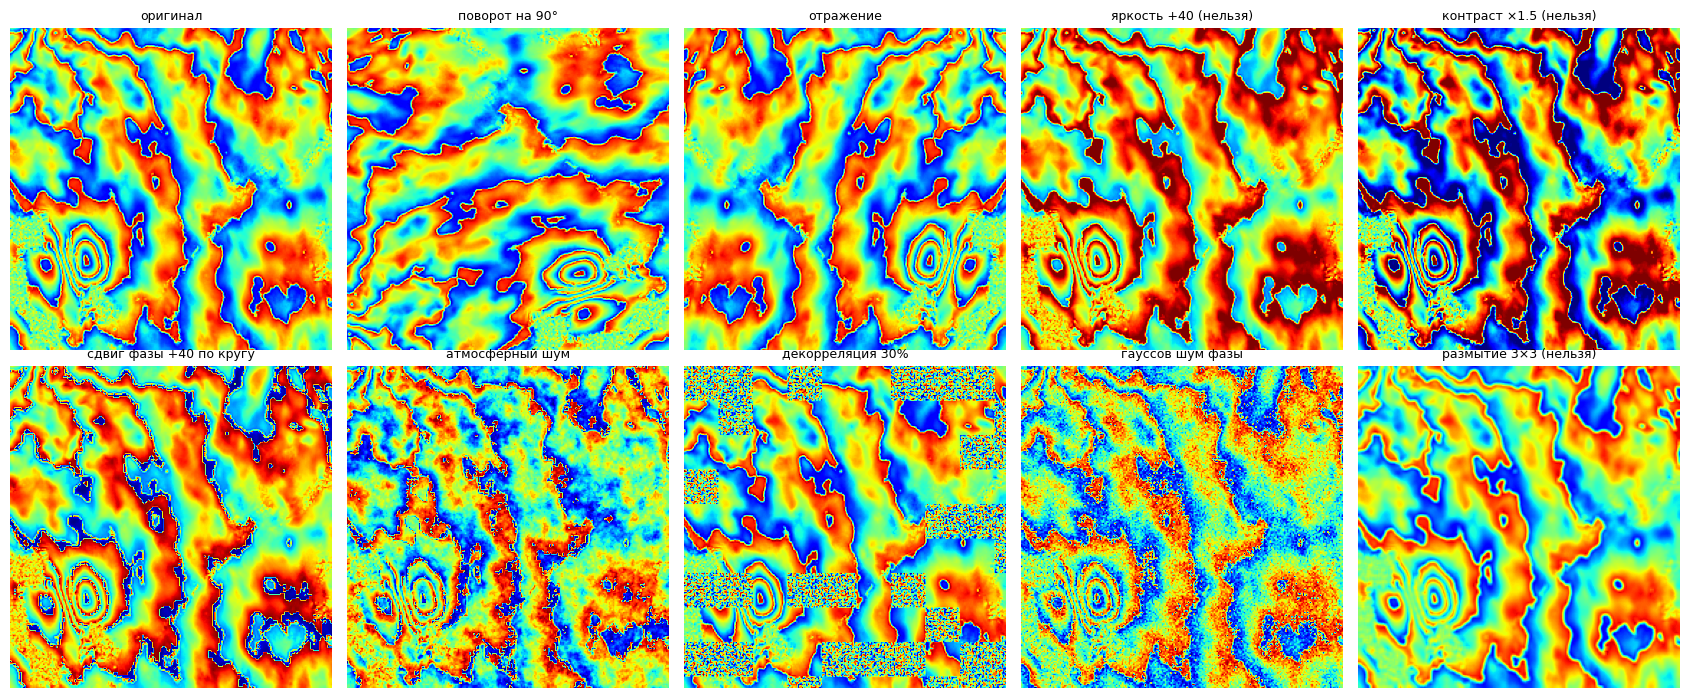

In [12]:
def wrap(x):                                   # вернуть значения в цикл 0..255
    return np.mod(np.round(x), 256).astype(np.uint8)

def atmo_noise(h, w, beta=2.5, seed=1):
    # плавный случайный шум со спектром 1/f^beta, похож на атмосферу
    r = np.random.default_rng(seed)
    f = np.hypot(np.fft.fftfreq(h)[:, None], np.fft.fftfreq(w)[None, :]); f[0, 0] = 1
    n = np.real(np.fft.ifft2(f**(-beta/2) * np.exp(2j*np.pi*r.random((h, w)))))
    return (n - n.mean())/n.std()

def decorrelate(a, frac=0.3, blob=24, seed=2):
    # заменяем случайные квадраты шумом, как на воде или снегу
    r = np.random.default_rng(seed); h, w = a.shape
    m = np.kron(r.random((h//blob+1, w//blob+1)) < frac, np.ones((blob, blob), bool))[:h, :w]
    out = a.copy(); out[m] = r.integers(0, 256, m.sum())
    return out

src = df[(df.cls == 'deformation') & (df.zero_frac < 0.01)].sort_values('fringe_frac').iloc[-50]
a = np.array(Image.open(src.path)); ph = a.astype(np.float32)*K
ops = {
 'оригинал': a,
 'поворот на 90°': np.rot90(a),
 'отражение': a[:, ::-1],
 'яркость +40 (нельзя)': np.clip(a.astype(int)+40, 0, 255).astype(np.uint8),
 'контраст ×1.5 (нельзя)': np.clip((a.astype(float)-128)*1.5+128, 0, 255).astype(np.uint8),
 'сдвиг фазы +40 по кругу': wrap(a.astype(int)+40),
 'атмосферный шум': wrap((ph + atmo_noise(224, 224))/K),
 'декорреляция 30%': decorrelate(a),
 'гауссов шум фазы': wrap((ph + rng.normal(0, 0.6, a.shape))/K),
 'размытие 3×3 (нельзя)': np.array(Image.fromarray(a).filter(ImageFilter.BoxBlur(1))),
}
fig, ax = plt.subplots(2, 5, figsize=(17, 7))
for ax_, (k, v) in zip(ax.ravel(), ops.items()):
    ax_.imshow(v, cmap='jet', vmin=0, vmax=255); ax_.set_title(k, fontsize=9); ax_.axis('off')
plt.tight_layout(); plt.show()


**Повороты и отражения** использовать можно: рисунок полос остаётся правдоподобным. Есть оговорка. Смещение измеряется вдоль луча спутника, и при отражении подъе может превратиться в опускание. Для задачи есть деформация или не» это не важно, но если потом захотим оценивать знак или величину смещения, отражения придётся убрать. В этом датасете такие аугментации уже применены, второй раз добавлять их смысла мало.

**Яркость, контраст, размытие** использовать нельзя. Значение пикселя это угол. Если прибавить 40 и обрезать по 255, полосы исказятся (на картинке появляются темно-красные пятна). Контраст растягивает фазу неравномерно. Размытие усредняет 255 и 0 в 128, и на границе цикла появляется ложная линия. Правильный аналог изменения яркости сдвиг фазы по кругу: прибавить число и взять остаток от деления на 256. Физически это то же самое, что выбрать другую опорную точку.

**Аугментации, которые имитируют реальные помехи**, кажутся нам самыми полезными:
- плавный шум, похожий на атмосферу (прибавляем к фазе и снова «сворачиваем»);
- случайный шум фазы;
- замена кусков патча шумом, как при декорреляции на воде или снегу;
- линейный наклон фазы по всему патчу (ошибка орбиты) на картинке не показан, но делается так же.

Они особенно пригодятся для Норильска, где много снега, воды и ложных полос от атмосферы.

## 6. Выводы

1. Датасет оказался не таким, как мы ожидали. В нем нет масок, это классификация патчей на два класса. Нет координат и нет привязки к землетрясениям.
2. Данные это фаза, а не яркость. Значения 0 и 255 соседние. Обычные приёмы для картинок (нормировка яркости, фотометрические аугментации) не подходят, на вход модели лучше подавать cos и sin фазы.
3. Баланс 50/50 искусственный. В реальной задаче положительных примеров будет очень мало, поэтому основная метрика у нас будет PR-AUC.
4. Пустые углы без данных встречаются почти только в классе `deformation` (1520 патчей против 9). Модель может использовать это как подсказку, и по ошибкам бейзлайна видно, что отчасти так и происходит. Такие области надо маскировать.
5. Половина патчей копии других с поворотом или отражением. Выборку нужно делить по группам копий. При случайном разбиении качество завышается (0.949 против 0.938 по accuracy).
6. Бейзлайн: HistGradientBoosting, accuracy 0.938, ROC-AUC 0.987, PR-AUC 0.985 на разбиении по группам. Почти такое же качество даёт модель на 8 простых признаках. Значит, датасет лёгкий. Он годится, чтобы отладить код и предобучить сеть на фазовых картинках, но о качестве на нашей задаче он ничего не скажет.

